# Kết quả và kiểm chứng: phát hiện chim nhỏ trong ảnh 4K (MVA 2023 SOD4SB)

Notebook này **chạy được ngay sau khi clone repo, chỉ cần CPU**: không cần GPU, ảnh hay trọng số. Mọi số trong bài báo
được tính lại từ các file đã lưu trong `results/verification/`:

| File | Nội dung |
|---|---|
| `val_predictions.npz` | Dự đoán đã lưu trên 879 ảnh validation: YOLOv8-M baseline và YOLOv8-M slicing (lượt chạy ảnh gốc), hai góc nhìn của lượt flip TTA (ảnh gốc, ảnh lật), GFL R50-FPN epoch 38. Mỗi dòng: `image_id, x, y, w, h, score`. |
| `val_predictions_sources.json` | Tên và SHA-256 của file dự đoán gốc mà mỗi mảng được trích ra (`scripts/export_verification_data.py`). |
| `mva_val_audited_coco.json` | Nhãn validation đã rà soát (bỏ 1 box trùng: 2.864 box). Phân phối lại theo `MVA_SOD4SB_LICENSE.txt`. |

Chỉ số: **AP50, AP75, AR100** (COCO, tối đa 100 box mỗi ảnh), tính bằng `evaluate.py` như mọi bảng trong bài báo.
Thời gian chạy cả notebook: khoảng 3 phút (phần lớn là gộp box của 879 ảnh).

In [1]:
import hashlib, json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / 'evaluate.py').exists():          # notebook opened from notebooks/
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / 'scripts')]
from evaluate import evaluate, SIZE_BUCKETS
import merge_tune, ensemble_wbf                   # the two fusion rules of the paper (flip TTA, final ensemble)

V = ROOT / 'results/verification'
ANN = V / 'mva_val_audited_coco.json'
ann = json.loads(ANN.read_text(encoding='utf-8'))
IDS = [im['id'] for im in ann['images']]
expected = json.loads((ROOT / 'data/mva_audited_v1/manifest.json').read_text())['splits']['val']['clean_sha256']
print('audited validation labels:', len(IDS), 'frames,', len(ann['annotations']), 'birds,',
      'SHA-256 matches manifest' if hashlib.sha256(ANN.read_bytes()).hexdigest() == expected else 'SHA-256 MISMATCH')

Z = np.load(V / 'val_predictions.npz')
SRC = {k: Z[k] for k in Z.files}
print({k: f'{len(v):,} boxes' for k, v in SRC.items()})

pct = lambda m: {k: round(100 * v, 1) for k, v in m.items()}
def to_coco(rows):
    return [dict(image_id=int(r[0]), category_id=0, bbox=[float(v) for v in r[1:5]], score=float(r[5])) for r in rows]
def per_image_xyxy(rows, i):
    b = rows[rows[:, 0] == i][:, 1:].copy(); b[:, 2] += b[:, 0]; b[:, 3] += b[:, 1]; return b
def xyxy_to_coco(i, boxes):
    return [dict(image_id=int(i), category_id=0, bbox=[float(x1), float(y1), float(x2 - x1), float(y2 - y1)], score=float(s))
            for x1, y1, x2, y2, s in boxes if x2 > x1 and y2 > y1]

audited validation labels: 879 frames, 2864 birds, SHA-256 matches manifest
{'baseline': '110,072 boxes', 'slicing': '53,827 boxes', 'plain': '53,854 boxes', 'flip': '51,198 boxes', 'gfl': '86,887 boxes'}


## 1. Từng nguồn dự đoán

So với các dòng tương ứng của **Bảng III** (từng bước của pipeline) và **Bảng V** (flip TTA) trong bài báo.
"YOLOv8-M slicing" là lượt chạy riêng trên ảnh gốc (dòng của Bảng III và VII). Lượt flip TTA chạy lại cùng mô hình trên
ảnh gốc và ảnh lật; hai lượt trên ảnh gốc là hai lần chạy GPU khác nhau nên lệch vài chục box (53.827 và 53.854),
nhưng cho cùng AP50/AP75/AR100.

In [2]:
PAPER = {  # AP50, AP75, AR100 (%) as printed in the paper
    'baseline': (70.2, 25.5, 43.9), 'slicing': (79.3, 38.8, 50.0), 'gfl': (74.9, 36.3, 46.6),
    'tta': (81.0, 40.3, 51.1), 'ensemble': (84.5, 45.8, 53.4)}
NAMES = {'baseline': 'YOLOv8-M baseline', 'slicing': 'YOLOv8-M slicing',
         'plain': '  lượt TTA: ảnh gốc', 'flip': '  lượt TTA: ảnh lật',
         'gfl': 'GFL R50-FPN (epoch 38)', 'tta': '+ flip TTA (WBF)', 'ensemble': '+ GFL, WBF một bước 1:1:1'}
PRED = {k: to_coco(v) for k, v in SRC.items()}
MET = {k: pct(evaluate(p, ANN)) for k, p in PRED.items()}
pd.DataFrame({NAMES[k]: m for k, m in MET.items()}).T

,AP50,AP75,AR100
YOLOv8-M baseline,70.2,25.5,43.9
YOLOv8-M slicing,79.3,38.8,50.0
lượt TTA: ảnh gốc,79.3,38.8,50.0
lượt TTA: ảnh lật,79.9,38.3,49.9
GFL R50-FPN (epoch 38),74.9,36.3,46.6


## 2. Flip TTA: gộp ảnh gốc và ảnh lật bằng WBF

Luật gộp `wbf` của `scripts/merge_tune.py`: cụm box có IoU > 0,55, toạ độ là trung bình có trọng số theo điểm,
điểm = tổng điểm / 2 nguồn. Box của ảnh lật đã được lật ngược về toạ độ ảnh gốc trước khi lưu.

In [3]:
t = time.time()
PRED['tta'] = []
for i in IDS:
    b = np.concatenate([per_image_xyxy(SRC['plain'], i), per_image_xyxy(SRC['flip'], i)])
    PRED['tta'] += xyxy_to_coco(i, merge_tune.wbf(b, voters=2))
MET['tta'] = pct(evaluate(PRED['tta'], ANN))
print(f"{time.time() - t:.0f} s;", MET['tta'], '| bài báo:', dict(zip(('AP50', 'AP75', 'AR100'), PAPER['tta'])))

15 s; {'AP50': 81.0, 'AP75': 40.3, 'AR100': 51.1} | bài báo: {'AP50': 81.0, 'AP75': 40.3, 'AR100': 51.1}


## 3. Ensemble cuối: GFL + YOLO + YOLO lật, một lần WBF

Luật `wbf` của `scripts/ensemble_wbf.py` với IoU 0,55 và trọng số 1:1:1 (Mục III-E của bài báo). Một box chỉ một
trong ba nguồn tìm thấy sẽ giữ 1/3 điểm, nên các false positive đơn lẻ bị đẩy xuống cuối danh sách.

In [4]:
t = time.time()
PRED['ensemble'] = []
for i in IDS:
    srcs = [per_image_xyxy(SRC[k], i) for k in ('gfl', 'plain', 'flip')]
    PRED['ensemble'] += xyxy_to_coco(i, ensemble_wbf.wbf(srcs, [1., 1., 1.], .55))
MET['ensemble'] = pct(evaluate(PRED['ensemble'], ANN))
print(f"{time.time() - t:.0f} s;", MET['ensemble'], '| bài báo:', dict(zip(('AP50', 'AP75', 'AR100'), PAPER['ensemble'])))

18 s; {'AP50': 84.5, 'AP75': 45.8, 'AR100': 53.4} | bài báo: {'AP50': 84.5, 'AP75': 45.8, 'AR100': 53.4}


## 4. Đối chiếu với Bảng III

Cột "lệch" là số tính lại trừ số trong bài báo (điểm %). Mọi ô phải bằng 0,0.

In [5]:
rows = []
for k in ('gfl', 'baseline', 'slicing', 'tta', 'ensemble'):
    for j, m in enumerate(('AP50', 'AP75', 'AR100')):
        rows.append(dict(bước=NAMES[k], chỉ_số=m, tính_lại=MET[k][m], bài_báo=PAPER[k][j], lệch=round(MET[k][m] - PAPER[k][j], 1)))
check = pd.DataFrame(rows)
print('Tất cả khớp với bài báo' if (check['lệch'].abs() < 0.05).all() else 'CÓ SỐ KHÔNG KHỚP')
check.pivot(index='bước', columns='chỉ_số', values='tính_lại').loc[[NAMES[k] for k in ('gfl', 'baseline', 'slicing', 'tta', 'ensemble')]]

Tất cả khớp với bài báo


chỉ_số,AP50,AP75,AR100
bước,,,
GFL R50-FPN (epoch 38),74.9,36.3,46.6
YOLOv8-M baseline,70.2,25.5,43.9
YOLOv8-M slicing,79.3,38.8,50.0
+ flip TTA (WBF),81.0,40.3,51.1
"+ GFL, WBF một bước 1:1:1",84.5,45.8,53.4


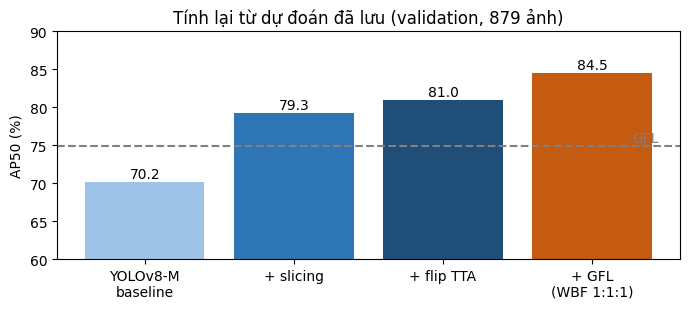

In [6]:
order = ['baseline', 'slicing', 'tta', 'ensemble']
fig, ax = plt.subplots(figsize=(7, 3.2))
vals = [MET[k]['AP50'] for k in order]
ax.bar(range(4), vals, color=['#9DC3E6', '#2E75B6', '#1F4E79', '#C55A11'])
for x, v in enumerate(vals): ax.text(x, v + 0.5, f'{v:.1f}', ha='center')
ax.axhline(MET['gfl']['AP50'], ls='--', c='gray'); ax.text(3.45, MET['gfl']['AP50'] + 0.5, 'GFL', color='gray', ha='right')
ax.set_xticks(range(4), ['YOLOv8-M\nbaseline', '+ slicing', '+ flip TTA', '+ GFL\n(WBF 1:1:1)'])
ax.set_ylim(60, 90); ax.set_ylabel('AP50 (%)'); ax.set_title('Tính lại từ dự đoán đã lưu (validation, 879 ảnh)')
plt.tight_layout(); plt.show()

## 5. AP50 theo kích thước chim (Bảng VII)

Nhóm theo $\sqrt{\text{diện tích}}$ của box nhãn. YOLO mạnh ở chim 8–16 px, GFL mạnh ở chim 32–64 px; ensemble giữ được
phần tốt hơn của cả hai.

In [7]:
PAPER_SIZE = {'baseline': (64.3, 80.3, 58.9), 'slicing': (78.4, 86.1, 58.4), 'tta': (80.2, 87.6, 60.6),
              'gfl': (67.4, 87.7, 72.4), 'ensemble': (83.5, 89.4, 72.4)}
size = {}
for k in PAPER_SIZE:
    size[NAMES[k]] = {f'{b} px': round(100 * evaluate(PRED[k], ANN, area_rng=r)['AP50'], 1) for b, r in SIZE_BUCKETS.items()}
size = pd.DataFrame(size).T
diff = size.values - np.array([PAPER_SIZE[k] for k in PAPER_SIZE])
print('Tất cả khớp với Bảng VII' if np.abs(diff).max() < 0.05 else f'CÓ SỐ KHÔNG KHỚP: lệch tối đa {np.abs(diff).max():.1f}')
size

Tất cả khớp với Bảng VII


,8-16 px,16-32 px,32-64 px
YOLOv8-M baseline,64.3,80.3,58.9
YOLOv8-M slicing,78.4,86.1,58.4
+ flip TTA (WBF),80.2,87.6,60.6
GFL R50-FPN (epoch 38),67.4,87.7,72.4
"+ GFL, WBF một bước 1:1:1",83.5,89.4,72.4


## 6. Split A / split B (Mục V-B)

Tập validation chia theo vị trí ảnh trong file nhãn: **split A** = vị trí lẻ, **split B** = vị trí chẵn. Ở đây chấm
luật gộp cuối cùng trên từng nửa. Mức tăng của ensemble so với flip TTA xuất hiện trên **cả hai** nửa, nên không phải
do chọn luật trên chính các ảnh dùng để chấm. (Bài báo còn chọn luật trên một nửa rồi chấm nửa kia; kết quả đã lưu
trong `results/ensemble/gfl+plain+flip.json`.)

In [8]:
A, B = IDS[1::2], IDS[0::2]
halves = pd.DataFrame({NAMES[k]: {'split A (AP50)': round(100 * evaluate(PRED[k], ANN, image_ids=A)['AP50'], 1),
                                  'split B (AP50)': round(100 * evaluate(PRED[k], ANN, image_ids=B)['AP50'], 1)}
                       for k in ('tta', 'ensemble')}).T
halves.loc['mức tăng'] = halves.iloc[1] - halves.iloc[0]
saved = json.loads((ROOT / 'results/ensemble/gfl+plain+flip.json').read_text())['held_out']
print(f"A: {len(A)} ảnh, B: {len(B)} ảnh. Đã lưu (chọn trên một nửa, chấm nửa kia): "
      f"chọn trên A -> B {100 * saved['its_AP50_on_even']:.1f}, chọn trên B -> A {100 * saved['its_AP50_on_odd']:.1f}")
halves.round(1)

A: 439 ảnh, B: 440 ảnh. Đã lưu (chọn trên một nửa, chấm nửa kia): chọn trên A -> B 84.8, chọn trên B -> A 84.1


,split A (AP50),split B (AP50)
+ flip TTA (WBF),80.7,81.4
"+ GFL, WBF một bước 1:1:1",84.1,85.0
mức tăng,3.4,3.6


## Ghi chú

- Dự đoán gốc được sinh bởi `scripts/eval_sahi_tta.py` (YOLO, chế độ `full` và `tta`) và `scripts/train_gfl_baseline.py`
  (GFL, đánh giá sau mỗi epoch); `scripts/export_verification_data.py` đóng gói chúng vào `val_predictions.npz`.
- Muốn chạy lại từ đầu (cần GPU, ảnh MVA và trọng số ở Release v1.0): xem README, mục "Tái lập từng thí nghiệm".
- Checkpoint GFL (epoch 38/50) được chọn theo AP50 validation; epoch cuối đạt 74,2% thay vì 74,9%, nên số của GFL và
  ensemble lạc quan khoảng 0,7 điểm (đã ghi trong bài báo).